In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import textwrap


In [357]:
df=pd.read_csv("Table3-SingleCellIsolates.csv")
# df[['Progenitor','SingleCellIsolate']]=df['Strain'].str.split("-", expand=True)
df

,Variant Type,Strain,Scaffold,Start (Mbp),End (Mbp),Variant subtype,Progenitor
0,Chromosomal Variation,12A1-SC1,8,scaffold start,scaffold end,reversion to diploid,12A1
1,Chromosomal Variation,UTEX2797-SC1,9,scaffold start,scaffold end,reversion to diploid,UTEX2797
2,Chromosomal Variation,"UTEX2797-SC2, UTEX2797-SC3",22,scaffold start,scaffold end,A1-derived trisomy,UTEX2797
3,Chromosomal Variation,"12A1-SC1, 12A1-SC3",25,scaffold start,scaffold end,A1-derived trisomy,12A1
4,Telomeric Variation,12A1-SC3,8,scaffold start,0.7,A2 telomeric segmental loss,12A1
5,Telomeric Variation,12A1-SC3,8,scaffold start,0.39,A2 telomeric segmental loss,12A1
6,Telomeric Variation,"UTEX2797-SC2, UTEX2797-SC3",8,1.25,scaffold end,A2 telomeric segmental duplication,UTEX2797
7,Telomeric Variation,"UTEX2797-SC2, UTEX2797-SC3",9,scaffold start,0.3,A2 telomeric segmental loss,UTEX2797
8,Interstitial Variation,12A1-SC1,2,3.19,3.39,A1 interstitial segmental loss,12A1
9,Interstitial Variation,12A1-SC2,8,0.65,2.05,A2 interstitial segmental duplication,12A1


In [358]:
dfgroup=df.groupby(["Variant Type"]).count().reset_index()
dfgroup=dfgroup[['Variant Type','Strain']]





In [209]:
dfgroup



,Variant Type,Strain
0,Chromosomal Variation,6
1,Interstitial Variation,9
2,Telomeric Variation,6


In [359]:
def plot_variant_type_counts(df):
    progenitors = sorted(df["Progenitor"].unique())
    
    # Grayscale colors for each progenitor
    progenitor_colors = {
        progenitors[0]: "#555555",
        progenitors[1]: "#BBBBBB"
    }

    counts = (
        df.groupby(["Variant Type", "Progenitor"])
        .size()
        .reset_index(name="count")
    )

    variant_types = ["Chromosomal Variation", "Interstitial Variation", "Telomeric Variation"]
    y = np.arange(len(variant_types))
    lefts = np.zeros(len(variant_types))

    fig, ax = plt.subplots(figsize=(3, 3))

    for progenitor in progenitors:
        sub = counts[counts["Progenitor"] == progenitor]
        widths = []
        for vtype in variant_types:
            row = sub[sub["Variant Type"] == vtype]
            widths.append(row["count"].values[0] if not row.empty else 0)

        ax.barh(y, widths, left=lefts, color=progenitor_colors[progenitor],
                edgecolor="white", linewidth=0.5, height=0.6, label=progenitor)
        lefts += np.array(widths)

    ax.set_yticks(y)
    ax.set_yticklabels(variant_types)
    ax.set_xlabel("Count")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    leg = ax.legend(title="Progenitor", bbox_to_anchor=(1.01, 0.5),
                    loc="center left", frameon=False)

    plt.savefig("single_cell_variants.pdf", dpi=150, bbox_inches="tight",
                bbox_extra_artists=[leg], pad_inches=0.3)
    plt.show()

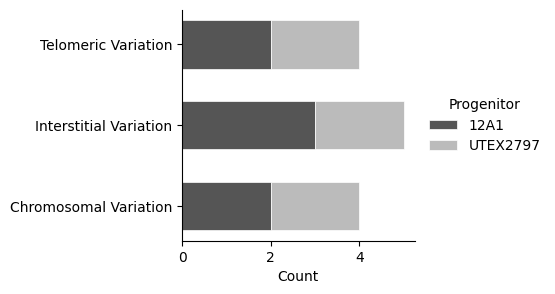

In [360]:
plot_variant_type_counts(df)



In [297]:
df=pd.read_csv("AllVariants.csv")





,Anomaly type,Strain,Scaffold,Anomaly start,Anomaly end,Anomaly subtype,Inferred A1 haplotype count,Inferred A2 haplotype count,Notes,potential chromosomal heterogeneity in culture,n_coverage_windows,avg_log2_coverage,avg_a1_allele_fraction,avg_a2_allele_fraction,avg_a1_allele_depth,avg_a2_allele_depth,n_snps
0,chromosomal variant,UTEX2827,9,0.00,3.65,A1 disomy,2,0,NaN,NaN,364.0,0.400440,0.989360,0.010640,151.421053,1.661404,10830.0
1,chromosomal variant,8027,27,0.00,1.75,A1 disomy,2,0,NaN,NaN,174.0,0.079966,0.989957,0.010043,77.969595,1.247814,5032.0
2,chromosomal variant,12A1,27,0.00,1.75,A1 disomy,2,0,NaN,NaN,174.0,0.079718,0.993937,0.006063,215.460851,0.981916,5032.0
3,chromosomal variant,13A5,27,0.00,1.75,A1 disomy,2,0,NaN,NaN,174.0,0.150855,0.993586,0.006414,212.944555,0.970390,5032.0
4,chromosomal variant,PK2297D4,27,0.00,1.75,A1 disomy,2,0,NaN,NaN,174.0,-0.014732,0.989203,0.010797,103.303657,1.600755,5032.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57,telomeric variant,RCC3703,3,4.56,5.05,telomeric segmental duplication,NaN,NaN,A2 strain,NaN,47.0,-1.595867,0.000712,0.999288,0.052591,48.409299,1312.0
58,telomeric variant,CCMP3037,18,0.00,0.22,telomeric segmental loss,NaN,NaN,A1 strain,NaN,23.0,-0.991925,0.999480,0.000520,60.773543,0.025785,892.0
59,telomeric variant,RCC3703,20,0.00,0.50,telomeric segmental loss,NaN,NaN,A2 strain,NaN,51.0,-1.363334,0.000696,0.999304,0.039838,46.988521,1481.0
60,telomeric variant,RCC3703,22,0.50,1.85,telomeric segmental loss,NaN,NaN,A2 strain,NaN,133.0,-1.098030,0.000959,0.999041,0.073510,46.818416,3877.0


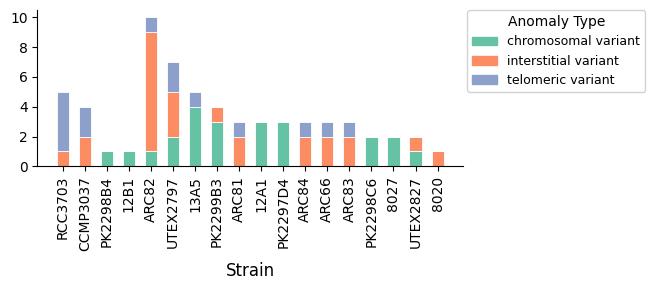

In [292]:
 
# Anomaly categories and colors
anomaly_types = ["chromosomal variant", "interstitial variant", "telomeric variant"]
colors = ["#66c2a5", "#fc8d62", "#8da0cb"]  # blue, orange, green
 
# Pivot to get counts per strain × anomaly type
counts = (
    df.groupby(["Strain", "Anomaly type"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=anomaly_types, fill_value=0)  # ensure consistent column order
)
 
# ── Strain ordering ───────────────────────────────────────────────────────────
priority_strains = ["RCC3703", "CCMP3037", "PK2298B4", "12B1"]
 
# Total anomalies per strain for sorting the remainder
totals = counts.sum(axis=1)
 
# Priority strains that actually exist in the data (preserving order)
ordered_priority = [s for s in priority_strains if s in counts.index]
 
# Remaining strains sorted by total anomalies descending
remaining = (
    totals.drop(index=ordered_priority, errors="ignore")
    .sort_values(ascending=False)
    .index.tolist()
)
 
strain_order = ordered_priority + remaining
counts = counts.reindex(strain_order)
 
# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(6, 3))
 
strains = counts.index.tolist()
x = np.arange(len(strains))
bar_width = 0.55
 
bottoms = np.zeros(len(strains))
 
for anomaly, color in zip(anomaly_types, colors):
    values = counts[anomaly].values
    ax.bar(x, values, bar_width, bottom=bottoms, color=color, label=anomaly, edgecolor="white", linewidth=0.6)
    bottoms += values
 
# Axis labels and formatting
ax.set_xticks(x)
ax.set_xticklabels(strains, rotation=90, fontsize=11)
ax.set_xlabel("Strain", fontsize=12, labelpad=8)
# ax.set_ylabel("Total Anomaly Count", fontsize=12, labelpad=8)
# ax.set_title("Anomaly Counts by Strain", fontsize=14, fontweight="bold", pad=12)
 
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(axis="both", labelsize=10)
 
# Legend
legend_patches = [
    mpatches.Patch(color=color, label=anomaly)
    for anomaly, color in zip(anomaly_types, colors)
]
ax.legend(
    handles=legend_patches,
    title="Anomaly Type",
    title_fontsize=10,
    fontsize=9,
    loc="upper left",
    bbox_to_anchor=(1.01, 1),
    borderaxespad=0,
    frameon=True,
    framealpha=0.85,
)
 
plt.tight_layout()
plt.subplots_adjust(right=0.78)  # make room for the legend
plt.savefig("all_strains_anomalies.pdf", dpi=150, bbox_inches="tight")
plt.show()

In [317]:
df_variantcount=df.groupby(['Strain']).count().reset_index()
df_variantcount=df_variantcount[['Strain','Anomaly type']]
df_variantcount['Strain']=df_variantcount['Strain'].astype(str)

In [318]:
isolation_dates=pd.read_csv("isolationdates.csv")
isolation_dates=isolation_dates.rename(columns={"Strain ID":"Strain"})
isolation_dates['Strain']=isolation_dates['Strain'].astype(str)
isolation_dates['Isolation Date']=2026-isolation_dates['Isolation Date']

In [319]:
df_variantcount = pd.merge(df_variantcount, isolation_dates, on="Strain", how="left")
df_variantcount

,Strain,Anomaly type,Isolation Date
0,12A1,3,16
1,12B1,1,16
2,13A5,5,16
3,8020,1,13
4,8027,2,13
5,ARC66,3,25
6,ARC81,3,24
7,ARC82,10,24
8,ARC83,3,24
9,ARC84,3,24


In [339]:
df_variantcount_hybrids=df_variantcount[ ~ df_variantcount.Strain.isin(["RCC3703", "CCMP3037", "PK2298B4", "12B1"])]
df_variantcount_hybrids

,Strain,Anomaly type,Isolation Date
0,12A1,3,16
2,13A5,5,16
3,8020,1,13
4,8027,2,13
5,ARC66,3,25
6,ARC81,3,24
7,ARC82,10,24
8,ARC83,3,24
9,ARC84,3,24
11,PK2297D4,3,6


/tmp/ipykernel_4172045/2266978512.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Isolation Date'] = pd.to_numeric(df['Isolation Date'], errors='coerce')
/tmp/ipykernel_4172045/2266978512.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Anomaly type'] = pd.to_numeric(df['Anomaly type'], errors='coerce')


Intercept:   1.8847
Coefficient: 0.1005
R² Score:    0.1065


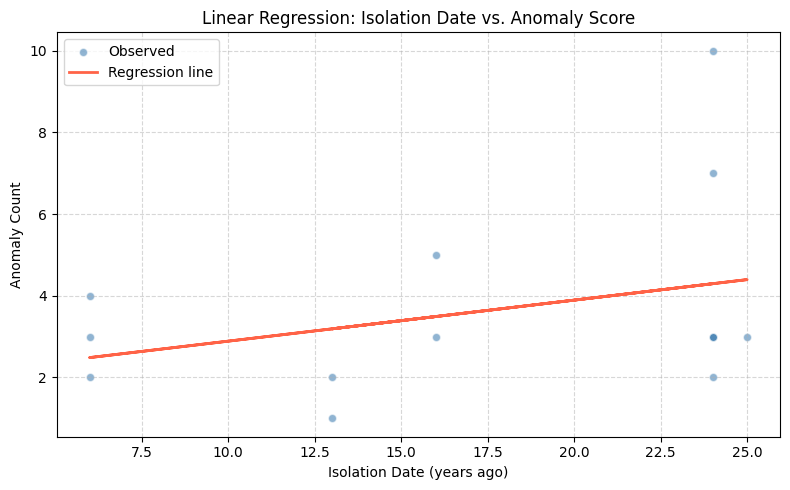

In [340]:
df = df_variantcount_hybrids

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Prepare the data ---
df['Isolation Date'] = pd.to_numeric(df['Isolation Date'], errors='coerce')
df['Anomaly type'] = pd.to_numeric(df['Anomaly type'], errors='coerce')

df_clean = df[['Isolation Date', 'Anomaly type']].dropna()

X = df_clean['Isolation Date'].values
y = df_clean['Anomaly type'].values

# --- 2. Fit linear regression using numpy ---
coef, intercept = np.polyfit(X, y, 1)

y_pred = coef * X + intercept

# R² calculated manually
ss_res = np.sum((y - y_pred) ** 2)
ss_tot = np.sum((y - y.mean()) ** 2)
r2 = 1 - (ss_res / ss_tot)

print(f"Intercept:   {intercept:.4f}")
print(f"Coefficient: {coef:.4f}")
print(f"R² Score:    {r2:.4f}")

# --- 3. Plot ---
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(X, y, alpha=0.6, label='Observed', color='steelblue', edgecolors='white')
ax.plot(X, coef * X + intercept, color='tomato', linewidth=2, label='Regression line')

ax.set_xlabel('Isolation Date (years ago)')
ax.set_ylabel('Anomaly Count')
ax.set_title('Linear Regression: Isolation Date vs. Anomaly Score')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("anomaly_vs_isolationdate.pdf")
plt.show()

/tmp/ipykernel_4172045/3930444329.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Isolation Date'] = pd.to_numeric(df['Isolation Date'], errors='coerce')
/tmp/ipykernel_4172045/3930444329.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Anomaly type'] = pd.to_numeric(df['Anomaly type'], errors='coerce')


Degree 1: R²=0.1065,  coefficients=[0.1005 1.8847]


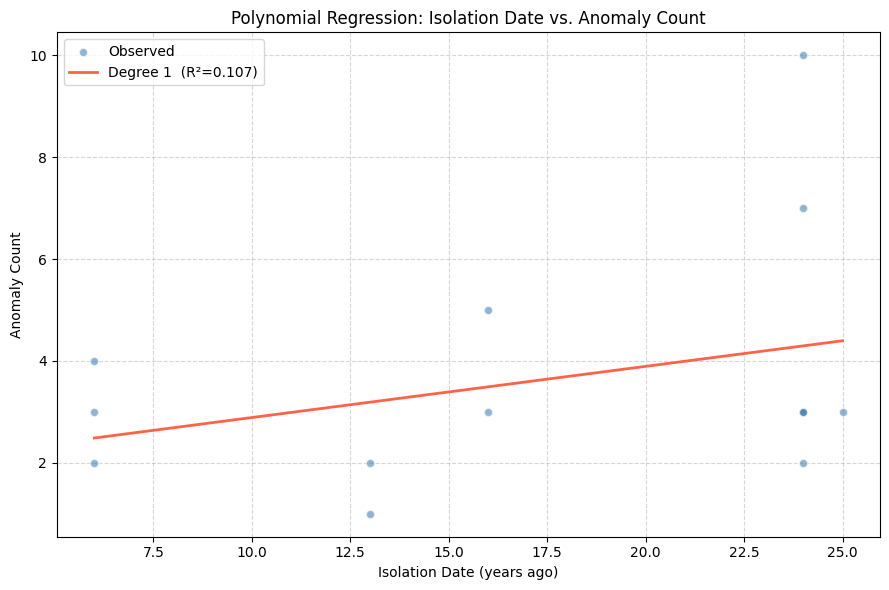

In [341]:
# --- 1. Prepare the data ---
df['Isolation Date'] = pd.to_numeric(df['Isolation Date'], errors='coerce')
df['Anomaly type'] = pd.to_numeric(df['Anomaly type'], errors='coerce')

df_clean = df[['Isolation Date', 'Anomaly type']].dropna()

X = df_clean['Isolation Date'].values
y = df_clean['Anomaly type'].values

# --- 2. Fit polynomials of degree 1–4 ---
degrees = [1]#, 2, 3]#, 4], 5, 6]
colors = ['tomato', 'darkorange', 'mediumseagreen', 'mediumpurple', 'black' ,'blue']

X_line = np.linspace(X.min(), X.max(), 300)  # smooth curve for plotting

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(X, y, alpha=0.6, label='Observed', color='steelblue', edgecolors='white', zorder=3)

for deg, color in zip(degrees, colors):
    coeffs = np.polyfit(X, y, deg)
    poly = np.poly1d(coeffs)

    y_pred = poly(X)
    ss_res = np.sum((y - y_pred) ** 2)
    ss_tot = np.sum((y - y.mean()) ** 2)
    r2 = 1 - (ss_res / ss_tot)

    ax.plot(X_line, poly(X_line), color=color, linewidth=2,
            label=f'Degree {deg}  (R²={r2:.3f})')
    print(f"Degree {deg}: R²={r2:.4f},  coefficients={np.round(coeffs, 4)}")

ax.set_xlabel('Isolation Date (years ago)')
ax.set_ylabel('Anomaly Count')
ax.set_title('Polynomial Regression: Isolation Date vs. Anomaly Count')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.5)
plt.savefig("anomaly_vs_isolationdate_polynomial.pdf")
plt.tight_layout()
plt.show()

In [343]:
CpHapDict={}
with open("CpHapAssignments.csv", "r") as infile:
    infile.readline()
    lines=infile.readlines()
    for line in lines:
        line=line.strip()
        line=line.split(",")
        Strain, CpHap=line[0], line[1]
        CpHapDict[Strain]=CpHap

{'8020': 'A1', 'ARC66': 'A1', 'ARC81': 'A1', 'ARC82': 'A1', 'ARC83': 'A1', 'ARC84': 'A1', 'PK2298C6': 'A1', 'PK2300D3': 'A1', 'UTEX2797': 'A1', '12A1': 'A2', '13A5': 'A2', '8027': 'A2', 'PK2297D4': 'A2', 'PK2299B3': 'A2', 'UTEX2827': 'A2'}


In [351]:
variant_df=pd.read_csv("AllVariants.csv")
variant_df['CpHap']=variant_df['Strain'].map(CpHapDict)
variant_df = variant_df.dropna(subset=['CpHap'])


In [352]:
variant_df

,Anomaly type,Strain,Scaffold,Anomaly start,Anomaly end,Anomaly subtype,Inferred A1 haplotype count,Inferred A2 haplotype count,Notes,potential chromosomal heterogeneity in culture,n_coverage_windows,avg_log2_coverage,avg_a1_allele_fraction,avg_a2_allele_fraction,avg_a1_allele_depth,avg_a2_allele_depth,n_snps,CpHap
0,chromosomal variant,UTEX2827,9,0.00,3.65,A1 disomy,2,0,NaN,NaN,364.0,0.400440,0.989360,0.010640,151.421053,1.661404,10830.0,A2
1,chromosomal variant,8027,27,0.00,1.75,A1 disomy,2,0,NaN,NaN,174.0,0.079966,0.989957,0.010043,77.969595,1.247814,5032.0,A2
2,chromosomal variant,12A1,27,0.00,1.75,A1 disomy,2,0,NaN,NaN,174.0,0.079718,0.993937,0.006063,215.460851,0.981916,5032.0,A2
3,chromosomal variant,13A5,27,0.00,1.75,A1 disomy,2,0,NaN,NaN,174.0,0.150855,0.993586,0.006414,212.944555,0.970390,5032.0,A2
4,chromosomal variant,PK2297D4,27,0.00,1.75,A1 disomy,2,0,NaN,NaN,174.0,-0.014732,0.989203,0.010797,103.303657,1.600755,5032.0,A2
5,chromosomal variant,PK2299B3,27,0.00,1.75,A1 disomy,2,0,NaN,NaN,174.0,0.019830,0.990301,0.009699,97.300477,1.323728,5032.0,A2
6,interstitial variant,ARC82,4,2.55,3.45,A1 interstitial segmental duplication,2,0-1,NaN,NaN,91.0,0.284307,0.803549,0.196451,72.332349,21.071522,3048.0,A1
7,interstitial variant,ARC82,8,1.30,1.55,A1 interstitial segmental duplication,2,1,NaN,NaN,26.0,0.437036,0.699293,0.300707,73.519585,31.951613,868.0,A1
8,interstitial variant,ARC66,26,1.48,1.54,A1 interstitial segmental duplication,2,1,NaN,NaN,7.0,0.595494,0.696884,0.303116,132.539394,60.272727,165.0,A1
9,interstitial variant,ARC81,26,1.48,1.54,A1 interstitial segmental duplication,2,1,NaN,NaN,7.0,0.678547,0.700374,0.299627,107.084849,48.169697,165.0,A1
